# Season Projections

Next-season projections for every player with NBA experience in the prior three seasons. Rookies are projected by the college model ([06_rookie_projections](06_rookie_projections.ipynb)).

| Method | Definition |
|---|---|
| Last season | The most recent season played, repeated |
| Marcel baseline | Rate stats: 5/4/3-weighted average of the last three seasons (times minutes), blended with the position-group average (G, F, C) and adjusted for age. Games: 0.5 x last season's share of team games + 0.1 x the season before + 0.25, age-adjusted. Minutes per game: 5/4/3 average weighted by games, age-adjusted |
| Model | Gradient boosted trees on the Marcel residuals, with three seasons of per-100, advanced and per-game stats, age, NBA season number, prior awards (MVP and DPOY votes, All-Star, All-NBA, All-Defense), changes in usage and minutes, and the number of teams played for |

Targets: games (scaled to 82), minutes per game, points, rebounds, assists, steals, blocks, turnovers and 3PA per 100 possessions, TS%, usage % and BPM.

Evaluation is walk-forward: each season from 2013-14 to 2025-26 is projected by models fit only on earlier seasons (from 2007-08). Rate-stat errors are minutes-weighted, for players with 500+ minutes in the projected season.

Source: Basketball-Reference (per 100 possessions, advanced, per-game tables, 2004-05 to 2025-26).

In [1]:
import pandas as pd
import plotly.io as pio

from nba_analytics.players.projections import (TARGETS, age_curves, build_frame, evaluate,
                                               player_seasons, project, walk_forward)
from nba_analytics.players.projections_plots import (plot_age_curves, plot_mae_by_season,
                                                     plot_mae_reduction, plot_projected_change,
                                                     plot_projection_bands)
from nba_analytics.players.rookies import project_draft_class, rookie_dataset

# Interactive in JupyterLab / VS Code; static PNG fallback where Plotly can't run (e.g. GitHub)
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].scale = 0.7
pd.set_option("display.max_rows", 100)

seasons = player_seasons(2005, 2026)
frame = build_frame(seasons, last=2026)
preds = walk_forward(frame, seasons, first_test=2014, last_test=2026)  # ~8 minutes

## Accuracy

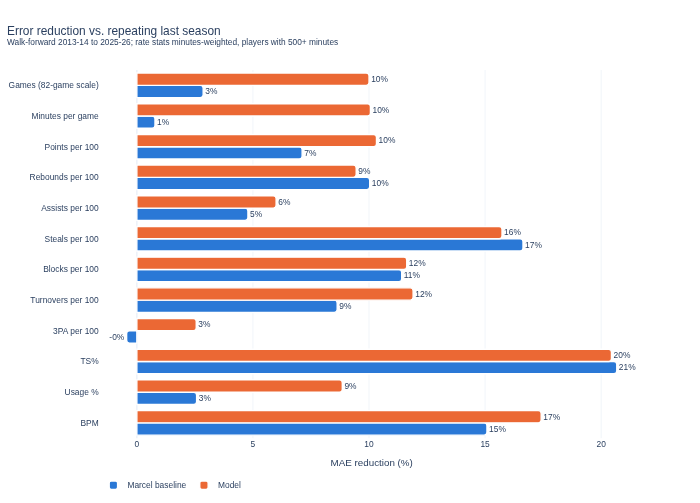

In [2]:
scores = evaluate(frame, preds)
plot_mae_reduction(scores).show()

In [3]:
mae = scores.pivot(index="target", columns="method", values="mae").loc[list(TARGETS.values())]
mae.columns = ["Last season", "Marcel", "Model"]
mae["Model vs. last season"] = (1 - mae["Model"] / mae["Last season"]).map("{:.1%}".format)
mae["Model vs. Marcel"] = (1 - mae["Model"] / mae["Marcel"]).map("{:.1%}".format)
mae.round(3)

,Last season,Marcel,Model,Model vs. last season,Model vs. Marcel
target,,,,,
Games (82-game scale),16.955,16.471,15.259,10.0%,7.4%
Minutes per game,4.601,4.565,4.138,10.1%,9.4%
Points per 100,2.882,2.677,2.584,10.3%,3.4%
Rebounds per 100,1.102,0.991,0.998,9.4%,-0.6%
Assists per 100,0.934,0.890,0.878,6.0%,1.3%
Steals per 100,0.326,0.272,0.275,15.7%,-1.1%
Blocks per 100,0.280,0.248,0.247,11.6%,0.2%
Turnovers per 100,0.498,0.455,0.439,11.9%,3.6%
3PA per 100,1.188,1.193,1.158,2.6%,3.0%


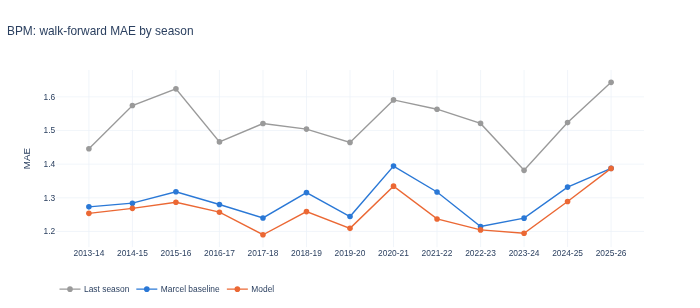

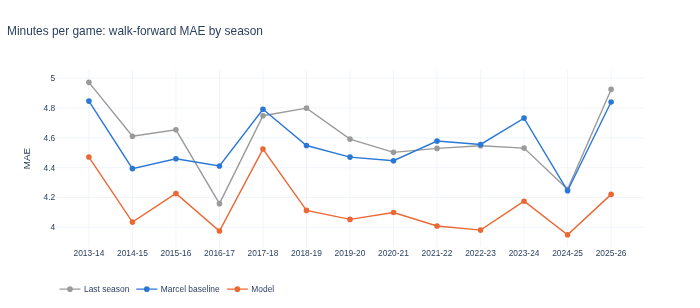

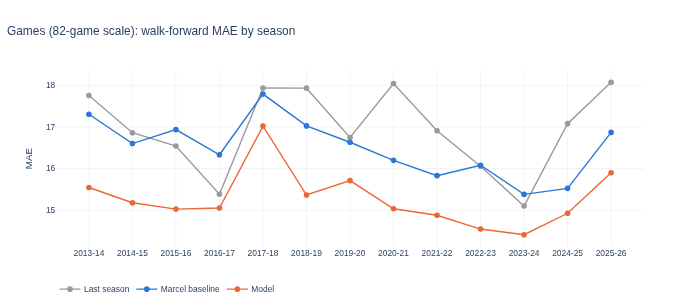

In [4]:
by_season = evaluate(frame, preds, by_season=True)
for target in ["bpm", "mp_per_g", "games"]:
    plot_mae_by_season(by_season, target).show()

## Aging curves

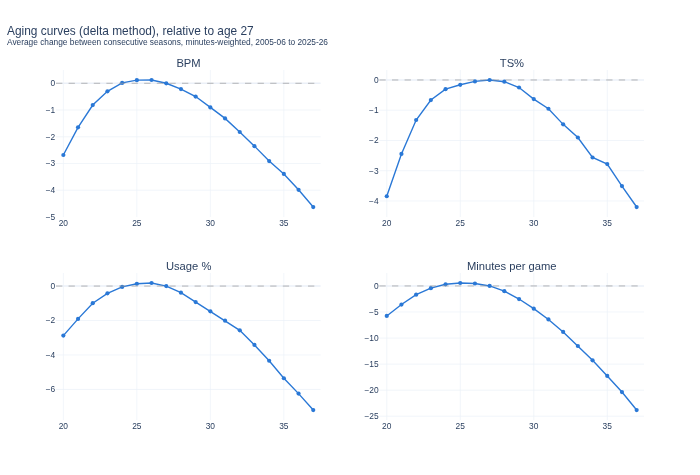

In [5]:
plot_age_curves(age_curves(seasons, before=2027),
                {"bpm": "BPM", "ts_pct": "TS%", "usg_pct": "Usage %",
                 "mp_per_g": "Minutes per game"}).show()

## 2026-27 projections

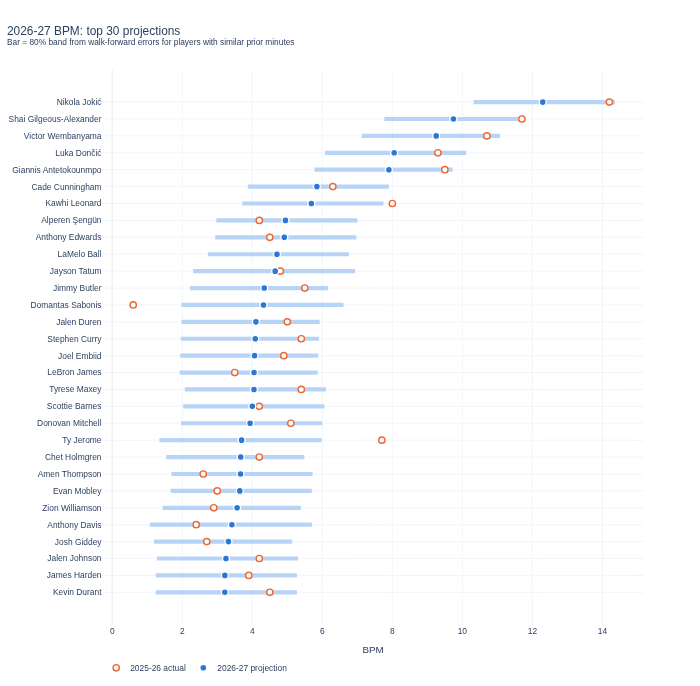

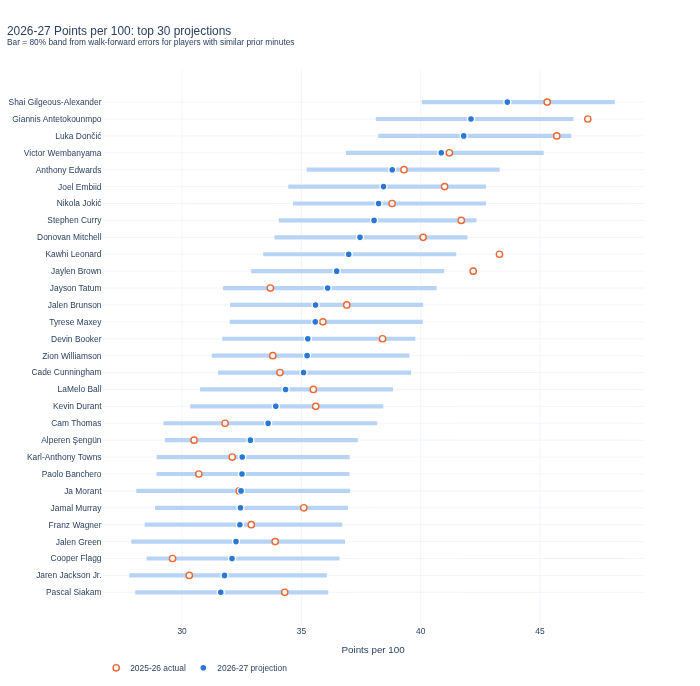

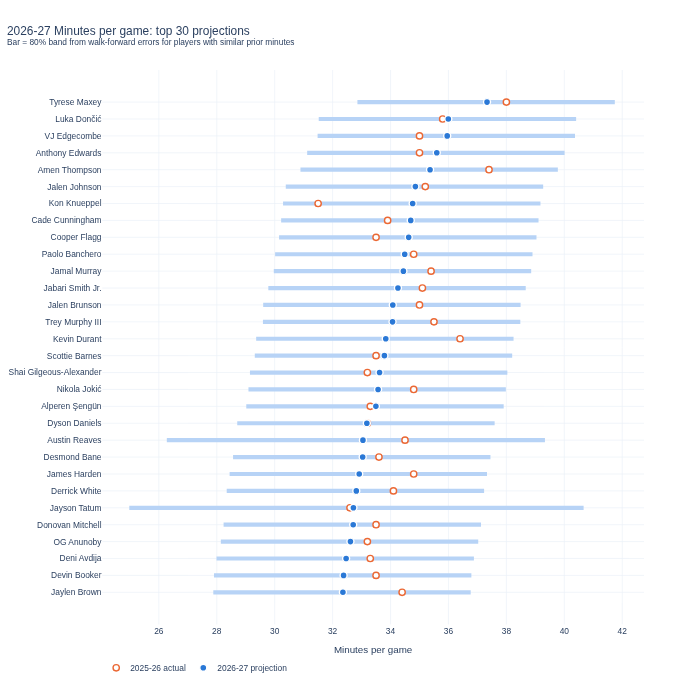

In [6]:
proj = project(frame, seasons, 2027, walk_forward_preds=preds)
for target in ["bpm", "pts_per_100", "mp_per_g"]:
    plot_projection_bands(proj, target).show()

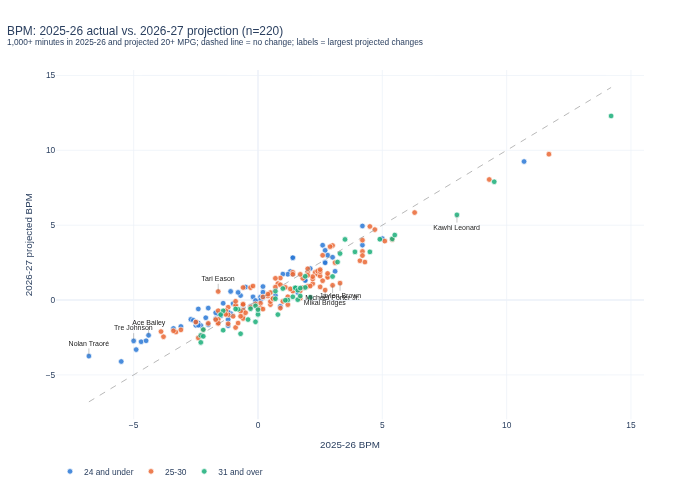

In [7]:
plot_projected_change(proj, "bpm").show()

### Projected 20+ minutes per game, by BPM

In [8]:
COLS = {"player": "Player", "pos_group": "Group", "age": "Age", "games": "G",
        "mp_per_g": "MPG", "pts_per_100": "PTS/100", "trb_per_100": "TRB/100",
        "ast_per_100": "AST/100", "stl_per_100": "STL/100", "blk_per_100": "BLK/100",
        "tov_per_100": "TOV/100", "fg3a_per_100": "3PA/100", "ts_pct": "TS%",
        "usg_pct": "USG%", "bpm": "BPM", "bpm_lo": "BPM low", "bpm_hi": "BPM high",
        "bpm_1": "Last season BPM"}
regulars = proj[proj["mp_per_g"] >= 20].sort_values("bpm", ascending=False)
regulars[list(COLS)].rename(columns=COLS).round(1).head(60).reset_index(drop=True)

,Player,Group,Age,G,MPG,PTS/100,TRB/100,AST/100,STL/100,BLK/100,TOV/100,3PA/100,TS%,USG%,BPM,BPM low,BPM high,Last season BPM
0,Nikola Jokić,C,31.0,60.2,33.6,38.2,16.6,14.3,2.0,1.0,4.7,6.2,65.9,29.2,12.3,10.3,14.4,14.2
1,Shai Gilgeous-Alexander,G,28.0,62.7,33.6,43.6,7.0,9.7,2.1,1.1,3.2,6.4,65.2,32.8,9.7,7.8,11.8,11.7
2,Victor Wembanyama,C,23.0,59.4,30.6,40.9,18.2,6.0,1.7,4.3,4.5,9.9,63.4,32.8,9.3,7.1,11.1,10.7
3,Luka Dončić,G,27.0,69.5,36.0,41.8,10.5,11.9,2.1,0.6,4.9,13.7,61.1,35.4,8.1,6.1,10.1,9.3
4,Giannis Antetokounmpo,F,32.0,50.1,29.2,42.1,15.9,9.1,1.4,1.3,4.7,1.4,64.3,32.7,7.9,5.8,9.7,9.5
5,Cade Cunningham,G,25.0,63.1,34.7,35.1,7.8,13.2,1.7,1.0,5.0,8.8,57.6,31.1,5.8,3.9,7.9,6.3
6,Kawhi Leonard,F,35.0,58.5,31.0,37.0,9.2,5.9,2.4,0.9,3.0,9.5,61.5,28.4,5.7,3.7,7.7,8.0
7,Alperen Şengün,C,24.0,67.7,33.5,32.9,14.4,8.9,1.8,1.2,4.5,3.1,57.8,28.1,4.9,3.0,7.0,4.2
8,Anthony Edwards,G,25.0,63.5,35.6,38.8,7.5,7.1,1.8,0.9,4.1,12.0,59.9,32.6,4.9,2.9,7.0,4.5
9,LaMelo Ball,G,25.0,65.1,29.4,34.3,7.6,11.7,2.0,0.4,4.7,17.6,56.1,30.5,4.7,2.7,6.8,4.7


### Largest projected BPM changes (1,000+ minutes in 2025-26, projected 20+ MPG)

In [9]:
change = regulars[regulars["mp_1"] >= 1000].assign(change=lambda d: d["bpm"] - d["bpm_1"])
CHANGE_COLS = {"player": "Player", "age": "Age", "bpm_1": "2025-26 BPM", "bpm": "2026-27 BPM",
               "change": "Change", "mp_1": "2025-26 minutes"}
change.nlargest(15, "change")[list(CHANGE_COLS)].rename(columns=CHANGE_COLS).round(1)

,Player,Age,2025-26 BPM,2026-27 BPM,Change,2025-26 minutes
223,Nolan Traoré,20.0,-6.8,-3.7,3.1,1243.0
178,Tre Johnson,20.0,-5.0,-2.7,2.3,1443.0
155,Tari Eason,25.0,-1.6,0.6,2.2,1549.0
81,Ace Bailey,20.0,-4.4,-2.4,2.0,1988.0
39,Bub Carrington,21.0,-4.7,-2.8,1.9,2271.0
87,Jarace Walker,23.0,-2.4,-0.6,1.8,1953.0
239,De'Andre Hunter,29.0,-3.9,-2.1,1.8,1176.0
141,Will Riley,20.0,-4.5,-2.7,1.8,1633.0
113,Kyle Filipowski,23.0,-1.1,0.6,1.7,1801.0
98,Nique Clifford,24.0,-4.9,-3.3,1.6,1882.0


In [10]:
change.nsmallest(15, "change")[list(CHANGE_COLS)].rename(columns=CHANGE_COLS).round(1)

,Player,Age,2025-26 BPM,2026-27 BPM,Change,2025-26 minutes
65,Kawhi Leonard,35.0,8.0,5.7,-2.3,2085.0
21,Jaylen Brown,30.0,3.3,1.1,-2.2,2443.0
5,Mikal Bridges,30.0,2.7,0.7,-2.0,2692.0
137,Michael Porter Jr.,28.0,3.0,1.0,-2.0,1689.0
44,Shai Gilgeous-Alexander,28.0,11.7,9.7,-2.0,2259.0
172,Grayson Allen,31.0,2.1,0.2,-1.9,1467.0
42,Nikola Jokić,31.0,14.2,12.3,-1.9,2265.0
62,Duncan Robinson,32.0,0.8,-1.0,-1.8,2113.0
54,Deni Avdija,26.0,4.3,2.5,-1.8,2199.0
161,Isaiah Joe,27.0,2.5,0.9,-1.6,1507.0


### 2026 rookies (college model)

In [11]:
rookies = project_draft_class(rookie_dataset(2010, 2026))
ROOKIE_COLS = {"draft_pick": "Pick", "player": "Player", "school": "School", "age": "Age",
               "proj_rookie_mpg": "MPG", "proj_rookie_bpm": "BPM"}
rookies[list(ROOKIE_COLS)].rename(columns=ROOKIE_COLS).round(1).head(30)

,Pick,Player,School,Age,MPG,BPM
0,1.0,AJ Dybantsa,BYU,19.4,31.3,-1.4
1,2.0,Darryn Peterson,Kansas,19.4,29.4,-1.4
2,3.0,Cameron Boozer,Duke,18.9,27.8,-0.0
3,4.0,Caleb Wilson,UNC,19.9,23.8,0.1
4,5.0,Keaton Wagler,Illinois,19.4,26.0,-1.8
5,6.0,Mikel Brown Jr.,Louisville,20.2,24.5,-3.1
6,7.0,Darius Acuff Jr.,Arkansas,19.6,23.9,-2.6
7,8.0,Kingston Flemings,Houston,19.5,24.6,-1.6
8,9.0,Morez Johnson Jr.,Michigan,20.4,18.7,-1.3
9,10.0,Brayden Burries,Arizona,20.8,22.8,-1.6
